<a href="https://colab.research.google.com/github/jimenezjos/Aplicaciones/blob/main/Lineade_Espera_de_un_Servidor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Solución Analítica Paso a Paso (Modelo M/M/1)
1. Factor de utilización ($\rho$)Es la proporción de tiempo que el servidor está ocupado.

$$\rho = \frac{\lambda}{\mu} = \frac{4}{6} = \frac{2}{3} \approx 0.6667$$

**El servidor está ocupado el 66.67% del tiempo, lo cual garantiza que el sistema es estable porque $\rho < 1$.**

2. Probabilidad de que el sistema esté vacío ($P_0$)Es la probabilidad de llegar y que el servidor esté desocupado.

$$P_0 = 1 - \rho = 1 - \frac{2}{3} = \frac{1}{3} \approx 0.3333$$

3. Probabilidad de que haya exactamente $n = 3$ clientes ($P_3$)Utilizamos la fórmula general $P_n = \rho^n P_0$.

$$P_3 = \left(\frac{2}{3}\right)^3 \left(\frac{1}{3}\right) = \left(\frac{8}{27}\right) \left(\frac{1}{3}\right) = \frac{8}{81} \approx 0.0988$$

4. Número promedio de unidades en la cola ($L_q$)El promedio de clientes esperando a ser atendidos.

$$L_q = \frac{\lambda^2}{\mu(\mu - \lambda)} = \frac{4^2}{6(6 - 4)} = \frac{16}{6(2)} = \frac{16}{12} = \frac{4}{3} \approx 1.3333 \text{ clientes}$$

5. Número promedio de unidades en el sistema ($L_s$)Los clientes en la fila más el que está siendo atendido.

$$L_s = L_q + \frac{\lambda}{\mu} = \frac{4}{3} + \frac{2}{3} = \frac{6}{3} = 2.0000 \text{ clientes}$$

6. Tiempo promedio que una unidad pasa en cola ($W_q$)El tiempo promedio de espera antes de ser atendido.

$$W_q = \frac{L_q}{\lambda} = \frac{4/3}{4} = \frac{1}{3} \approx 0.3333 \text{ unidades de tiempo}$$

7. Tiempo promedio en el sistema ($W_s$)Aunque no lo imprimiste en tu código, es un dato que siempre va de la mano. Es el tiempo en cola más el tiempo de servicio.

$$W_s = W_q + \frac{1}{\mu} = \frac{1}{3} + \frac{1}{6} = \frac{2}{6} + \frac{1}{6} = \frac{3}{6} = 0.5000 \text{ unidades de tiempo}$$

In [1]:
import random as rm
import matplotlib.pyplot as plt

In [2]:
def fila(tiempo_total, tasa_llegada, tasa_servicio):
    t = 0
    N_A = 0
    N_D = 0
    n = 0

    t_A = rm.expovariate(tasa_llegada)
    t_D = float('inf')
    tiempos_historico = [0]
    clientes_historico = [0]

    while t <= tiempo_total:
        if t_A <= t_D and t_A <= tiempo_total:
            t = t_A
            N_A += 1
            n += 1
            t_A = t + rm.expovariate(tasa_llegada)
            if n == 1:
                t_D = t + rm.expovariate(tasa_servicio)
        elif t_D < t_A and t_D <= tiempo_total:
            t = t_D
            N_D += 1
            n -= 1
            if n == 0:
                t_D = float('inf')
            else:
                t_D = t + rm.expovariate(tasa_servicio)
        else:
            break
        tiempos_historico.append(t)
        clientes_historico.append(n)
    return tiempos_historico, clientes_historico


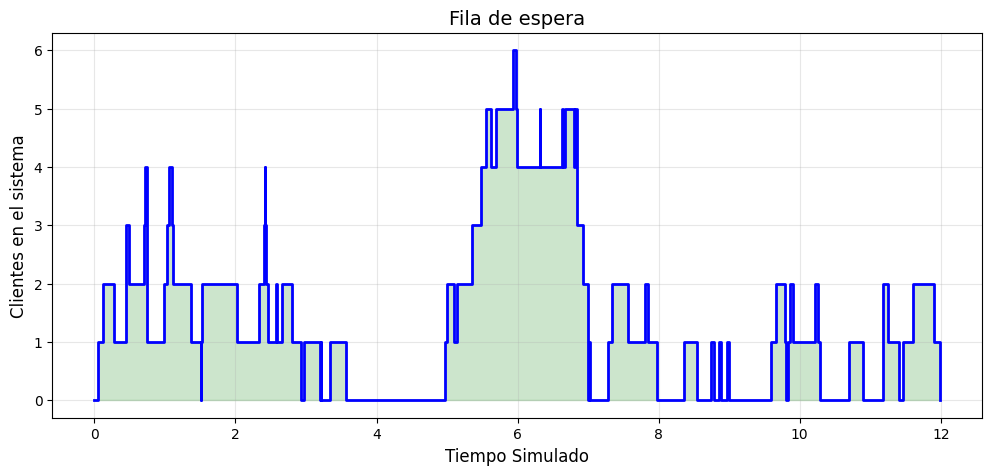

In [12]:
llegadas = 4
servicio = 6
tiempo_sim = 12

T, N = fila(tiempo_total=tiempo_sim, tasa_llegada=llegadas, tasa_servicio=servicio)

plt.figure(figsize=(12, 5))
plt.step(T, N, where='post', color='blue', linewidth=2)
plt.fill_between(T, 0, N, step="post", alpha=0.2, color='green')
plt.xlabel('Tiempo Simulado', fontsize=12)
plt.ylabel('Clientes en el sistema', fontsize=12)
plt.title('Fila de espera', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
lam = llegadas
mu = servicio

if lam < mu:

    rho = lam / mu
    print(f"Factor de utilización (rho): {rho:.4f}")

    P0 = 1 - rho
    print(f"Probabilidad de que el sistema esté vacío (P0): {P0:.4f}")

    n_ejemplo = 3
    Pn = (rho ** n_ejemplo) * P0
    print(f"Probabilidad de que haya exactamente {n_ejemplo} clientes (P{n_ejemplo}): {Pn:.4f}")

    Lq = (lam ** 2) / (mu * (mu - lam))
    print(f"Número promedio de unidades en cola (Lq): {Lq:.4f}")

    Ls = Lq + (lam / mu)
    print(f"Número promedio de unidades en el sistema (Ls): {Ls:.4f}")

    Wq = Lq / lam
    print(f"Tiempo promedio que una unidad pasa en cola (Wq): {Wq:.4f}")

else:
    print("El sistema es inestable: La tasa de llegadas es mayor o igual a la tasa de servicio")
    print("La fila crecerá hasta el infinito y las fórmulas de estado estable no aplican")

Factor de utilización (rho): 0.6667
Probabilidad de que el sistema esté vacío (P0): 0.3333
Probabilidad de que haya exactamente 3 clientes (P3): 0.0988
Número promedio de unidades en cola (Lq): 1.3333
Número promedio de unidades en el sistema (Ls): 2.0000
Tiempo promedio que una unidad pasa en cola (Wq): 0.3333
